# Create a dataset of faces dividing them in fake and real

### Libraries, constants and pre-trained MTCNN

Install FaceNet-PyTorch if it's not already installed (it includes the pre-trained MTCNN model):

In [37]:
%%capture
!pip install facenet-pytorch Pillow pandas tqdm

Import the necessary libraries:

In [6]:
import numpy as np
import torch
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
import os 
import cv2
from random import randint
from PIL import Image
from tqdm import tqdm

In [7]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(f'Running on device: {device}')

Running on device: cuda:0


Import the pre-trained MTCNN:

[Guide on how to use MTCNN](https://www.kaggle.com/code/timesler/guide-to-mtcnn-in-facenet-pytorch/notebook)

In [8]:
from facenet_pytorch import MTCNN

Constants:

In [9]:
from constants import ORIGINAL_VIDEOS_FOLDER, FAKE_VIDEOS_FOLDER, FACES_FOLDER, FACES_REAL, FACES_FAKE

Lists of fake and real videos:

In [10]:
import os

# --- CORRECTED: Use os.walk to find all .mp4 files recursively ---

# Define the root directories for your videos
FAKE_VIDEOS_ROOT = "/home/fakubwoy/DeepfakeDetection-25/data/manipulated_sequences"
ORIGINAL_VIDEOS_ROOT = "/home/fakubwoy/DeepfakeDetection-25/data/original_sequences"

# Create a list of full paths to all FAKE video files
FAKE_VIDEOS = []
for root, dirs, files in os.walk(FAKE_VIDEOS_ROOT):
    for filename in files:
        if filename.endswith(".mp4"):
            FAKE_VIDEOS.append(os.path.join(root, filename))

# Create a list of full paths to all ORIGINAL video files
ORIGINAL_VIDEOS = []
for root, dirs, files in os.walk(ORIGINAL_VIDEOS_ROOT):
    for filename in files:
        if filename.endswith(".mp4"):
            ORIGINAL_VIDEOS.append(os.path.join(root, filename))

### Save some examples of videos

In [11]:
import os
import cv2

# Constants
FAKE_VIDEOS_ROOT = "/home/fakubwoy/DeepfakeDetection-25/data/manipulated_sequences"
REAL_VIDEOS_ROOT = "/home/fakubwoy/DeepfakeDetection-25/data/original_sequences"
OUTPUT_FOLDER = "/home/fakubwoy/DeepfakeDetection-25/examples"
NUM_EXAMPLES = 20
FRAME_IDX = 60

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

# --- CORRECTED: Collect all video paths using os.walk ---
fake_video_paths = []
for root, dirs, files in os.walk(FAKE_VIDEOS_ROOT):
    for filename in files:
        if filename.endswith(".mp4"):
            fake_video_paths.append(os.path.join(root, filename))

real_video_paths = []
for root, dirs, files in os.walk(REAL_VIDEOS_ROOT):
    for filename in files:
        if filename.endswith(".mp4"):
            real_video_paths.append(os.path.join(root, filename))

# Limit to NUM_EXAMPLES
fake_video_paths = fake_video_paths[:NUM_EXAMPLES]
real_video_paths = real_video_paths[:NUM_EXAMPLES]

# Process fake videos
print("--- Processing Fake Videos ---")
for idx, path in enumerate(fake_video_paths):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        print(f"[ERROR] Failed to open fake video: {path}")
        continue
    cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
    success, frame = cap.read()
    if not success or frame is None:
        print(f"[ERROR] Could not read frame {FRAME_IDX} from {path}")
        cap.release()
        continue
    out_path = os.path.join(OUTPUT_FOLDER, f"fake_frame_{idx}.jpg")
    cv2.imwrite(out_path, frame)
    print(f"[INFO] Saved: {out_path}")
    cap.release()

# Process real videos
print("\n--- Processing Real Videos ---")
for idx, path in enumerate(real_video_paths):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        print(f"[ERROR] Failed to open real video: {path}")
        continue
    cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
    success, frame = cap.read()
    if not success or frame is None:
        print(f"[ERROR] Could not read frame {FRAME_IDX} from {path}")
        cap.release()
        continue
    out_path = os.path.join(OUTPUT_FOLDER, f"real_frame_{idx}.jpg")
    cv2.imwrite(out_path, frame)
    print(f"[INFO] Saved: {out_path}")
    cap.release()

--- Processing Fake Videos ---
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_0.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_1.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_2.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_3.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_4.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_5.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_6.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_7.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_8.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_9.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_10.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examples/fake_frame_11.jpg
[INFO] Saved: /home/fakubwoy/DeepfakeDetection-25/examp

### Plot some examples

post_process avoids image normalization to be able to plot the images:

In [12]:
# Load the MTCNN in evaluation mode
# -> Evaluation deactivates Dropout layers, which speeds up the inference
mtcnn = MTCNN(select_largest=False, post_process=False, device=device).eval()

In [13]:
def plot_example(num_samples=3):
    """Plot the first frame of a fake video and the extracted face."""
    _, ax = plt.subplots(nrows=num_samples, ncols=2, figsize=(18, 10))
    
    for i in range(num_samples):
        video_idx = randint(0, len(FAKE_VIDEOS) - 1)
        # --- CORRECTED: Directly use the full path from the list ---
        video_path = FAKE_VIDEOS[video_idx]
        
        fake_video = cv2.VideoCapture(video_path)
        
        if not fake_video.isOpened():
            print(f"Error: Could not open video file: {video_path}")
            continue
            
        success, fake_frame = fake_video.read()
        
        if not success or fake_frame is None:
            print(f"Error: Could not read frame from video file: {video_path}")
            fake_video.release()
            continue

        fake_video.release()
        fake_frame = cv2.cvtColor(fake_frame, cv2.COLOR_BGR2RGB)

        frame = Image.fromarray(fake_frame)
        face = mtcnn(frame)

        if face is not None:
            face = face.permute(1, 2, 0)
            face = face.cpu().detach().int().numpy()
            ax[i, 1].imshow(face)
            ax[i, 1].set_title("Fake (face)")
        else:
            ax[i, 1].set_title("Face not detected")

        ax[i, 0].imshow(fake_frame)
        ax[i, 0].set_title("Fake (full image)")
        ax[i, 0].axis("off")
        ax[i, 1].axis("off")
    
    plt.tight_layout()
    plt.show()

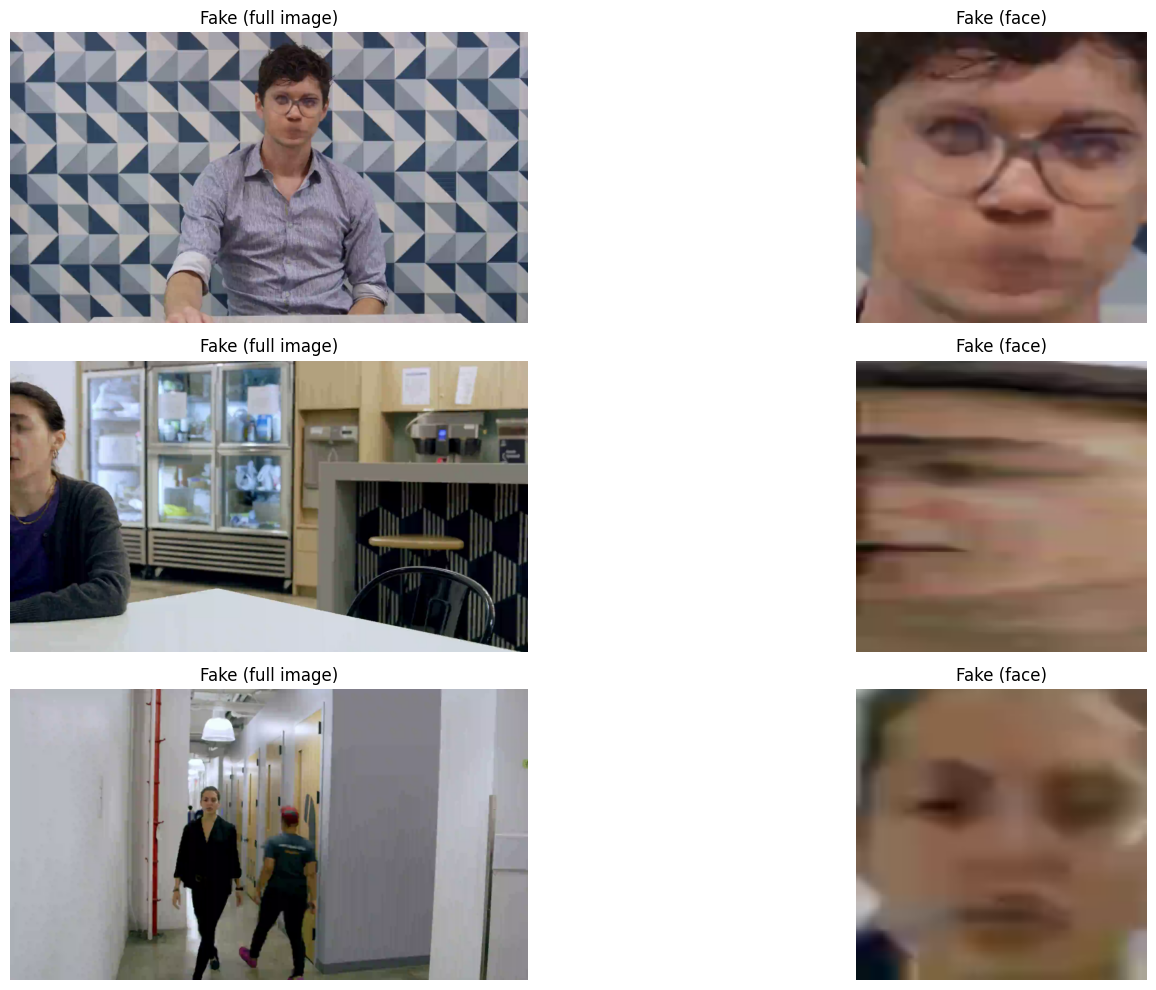

In [57]:
plot_example()

In [14]:
examples_folder = "../examples/"

for i in range(1, 21):
    video_idx = randint(0, len(FAKE_VIDEOS)-1)
    fake_video = cv2.VideoCapture(
        os.path.join(FAKE_VIDEOS_FOLDER, FAKE_VIDEOS[video_idx]
    ))
    _, fake_frame = fake_video.read()
    fake_frame = cv2.cvtColor(fake_frame, cv2.COLOR_BGR2RGB)
    Image.fromarray(fake_frame).save(os.path.join(examples_folder, f'fake_frame_{i}.png'))

for i in range(1, 21):
    video_idx = randint(0, len(ORIGINAL_VIDEOS)-1)
    real_video = cv2.VideoCapture(
        os.path.join(ORIGINAL_VIDEOS_FOLDER, ORIGINAL_VIDEOS[video_idx]
    ))
    _, real_frame = real_video.read()
    real_frame = cv2.cvtColor(real_frame, cv2.COLOR_BGR2RGB)
    Image.fromarray(real_frame).save(os.path.join(examples_folder, f'real_frame_{i}.png'))

### Create the new dataset

Create a new folder where we'll store the face images:

In [67]:
!rm -rf ../data/faces/real

In [68]:
!rm -rf ../data/faces

In [69]:
os.mkdir(FACES_FOLDER)
os.mkdir(FACES_REAL)
os.mkdir(FACES_FAKE)

In [1]:
!ls ../data/faces

faces.csv  fake  real


Function to store the face images:

In [74]:
def get_face_name_from_video_name(video_name):
    """Get the face name from the video name"""
    img_name = video_name.split(".mp4")[0] # Remove the .mp4 extension
    return img_name + "_face.png" # Add the _face.png extension

In [76]:
def save_frame(fake_frame, video_name, faces_folder):
    fake_frame = cv2.cvtColor(fake_frame, cv2.COLOR_BGR2RGB) # BGR -> RGB

    frame = Image.fromarray(fake_frame)
    face = mtcnn(frame) # extract the face from the frame

    # if the face is not found on the image, we do not save it
    if face is None: return

    # (CHANNELS, HEIGHT, WIDTH) -> (HEIGHT, WIDTH, CHANNELS)
    face = face.permute(1, 2, 0)
    # face is a tensor where the pixel values are float32 values
    # -> move it to the CPU, convert it to int values and then to a numpy array 
    face = face.cpu().detach().numpy().astype(np.uint8)

    # Save the face
    img_name = get_face_name_from_video_name(video_name)
    Image.fromarray(face).save(os.path.join(faces_folder, img_name))

In [92]:
import os
import cv2
from tqdm import tqdm
from PIL import Image
import numpy as np

def save_face(videos_names, faces_folder, is_real=None):
    """
    Save the face of the video in the faces_folder.
    Creates the directory if it doesn't exist and skips already processed videos.
    """
    folder_tag = "real" if is_real else "fake"
    
    # --- FIX START ---
    # Ensure the output directory exists before trying to list its contents.
    os.makedirs(faces_folder, exist_ok=True)
    
    # Get a set of processed video prefixes for fast lookup.
    processed_files = os.listdir(faces_folder)
    processed_stems = set(f.split('_f')[0] for f in processed_files)
    # --- FIX END ---

    for i in tqdm(range(len(videos_names)), desc=f"Extracting faces from {folder_tag} folder"):
        video_path = videos_names[i]
        
        # Get the stem of the current video to check if it's processed.
        video_stem = os.path.splitext(os.path.basename(video_path))[0]
        
        if video_stem in processed_stems:
            continue  # Skip this video as it's already processed.
            
        video_capture = cv2.VideoCapture(video_path)
        
        if not video_capture.isOpened():
            continue

        frame_skip = 60 if is_real else 90
        
        count = 0
        frame_num = 0
        ret, frame_data = video_capture.read()
        while ret:
            base_video_name = os.path.basename(video_path)
            # Use os.path.splitext for a more reliable way to handle filenames
            name_stem, name_ext = os.path.splitext(base_video_name)
            name = f"{name_stem}_f{frame_num}{name_ext}"
            
            # save_frame function is assumed to be defined elsewhere
            save_frame(frame_data, name, faces_folder)

            frame_num += 1
            count += frame_skip
            video_capture.set(cv2.CAP_PROP_POS_FRAMES, count)
            ret, frame_data = video_capture.read()
        
        video_capture.release()

In [94]:
# Corrected Code for Cell [78]
# Store the faces of the real videos:
save_face(ORIGINAL_VIDEOS, FACES_REAL, is_real=True)

# Store the faces of the fake videos:
save_face(FAKE_VIDEOS, FACES_FAKE, is_real=False)

Extracting faces from fake folder: 100%|██████████| 3068/3068 [2:16:35<00:00,  2.67s/it]  


### Save the images names with their label as a csv file

In [15]:
import os
real_faces = os.listdir(FACES_REAL)
real_faces = np.array(list(zip(real_faces, ["real"]*len(real_faces))))
fake_faces = os.listdir(FACES_FAKE)
fake_faces = np.array(list(zip(fake_faces, ["fake"]*len(fake_faces))))

faces = np.concatenate((real_faces, fake_faces))

# shuffle the data
np.random.shuffle(faces)

In [16]:
df = pd.DataFrame(faces, columns=["name", "label"])


In [17]:
df.head(30)

,name,label
0,02_14__walking_and_outside_surprised__3IUBEKCT...,fake
1,10__outside_talking_still_laughing_f3_face.png,real
2,03_01__hugging_happy__ISF9SP4G_f9_face.png,fake
3,17__walking_and_outside_surprised_f4_face.png,real
4,01_04__podium_speech_happy__GBC7ZGDP_f9_face.png,fake
5,06__talking_against_wall_f1_face.png,real
6,01_11__outside_talking_pan_laughing__LL4RUKZA_...,fake
7,14_26__talking_angry_couch__ILLP29ZH_f13_face.png,fake
8,03_20__talking_angry_couch__9NFWR304_f2_face.png,fake
9,08_16__talking_against_wall__8Q7JCS95_f0_face.png,fake


In [18]:
df.to_csv(os.path.join(FACES_FOLDER, "faces.csv"))